<a href="https://colab.research.google.com/github/25f2009371-oss/Deep-Learning-with-pytorch-My-notes-and-work-/blob/main/02_Pytorch_Workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#*Pytorch* WorkFlow


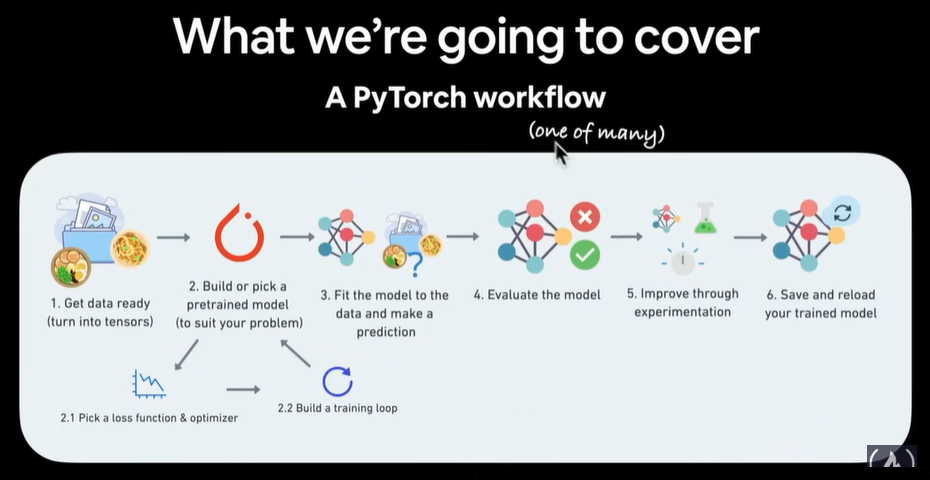

1. data prepare and load
2. build model
3. fitting the model to data training
4. make prediction and evaluate a model inference
5. moding and loading a model
6. putting it all together

In [1]:
import torch
from torch import nn ## nn contain all of pytorch building block of neural network
import matplotlib.pyplot as plt


In [2]:
torch.__version__

'2.11.0+cpu'

# Data(preparing and loading)

data can be almost anything... in machine learnign

* Excel spreadsheet
* Images of any kind
* Videos
* Audios
* DNA
* Text

Machine leanring is a game of two parts:
1. Get data into numerical representation .
2. Build a model to learn patterns in that numerical representation.

To showcase this, lets create some *known* data using linear regression formula


we will use a linear regression formula to make a straith line with known parameters

In [23]:
#Create *known* parameters
weight=0.7
bias=0.3


#create
start=0
end=1
step=0.02

X=torch.arange(start,end,step).unsqueeze(dim=1)
y=weight*X+bias  #gradient+intercept or its linear regression formula

X[:10],y[:10]



(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [24]:
len(X),len(y)

(50, 50)

##Spilitting data into training and test sets (one of the most important things in machine leanring general)

Lets create a trainign and test set with data



In [25]:
#Create a train/test split

train_split=int(0.8*len(X))

X_train,y_train=X[:train_split],y[:train_split]
X_test,y_test=X[train_split:],y[train_split:]

In [26]:
print(len(X_train),len(y_train),len(X_test),len(y_test))

40 40 10 10


How might we better visualize our data?

This is where data explorer's motto come in!

"visualize, visualize, visualize!"


In [29]:
def plot_prediction(train_data=X_train,
                    train_labels=y_train,
                    test_data=X_test,
                    test_labels=y_test,
                    predictions=None):
  """
  Plot training data, test data and compare predictions
  """
  plt.figure(figsize=(10,7))
  #Setting labels
  plt.xlabel("Parameter(only one here)")
  plt.ylabel("Output(Real)")


  #Plot training data in Blue
  plt.scatter(train_data,train_labels,c="b",s=8,label="Training data")
  #Plot training data in Red
  plt.scatter(test_data,test_labels,c="r",s=8,label="Test data")

  #Are there prediction??
  if predictions is not None:
    plt.scatter(test_data,predictions,c="violet",s=8,label="Predictions")
#show the labels through legend

  plt.legend(prop={"size":14})


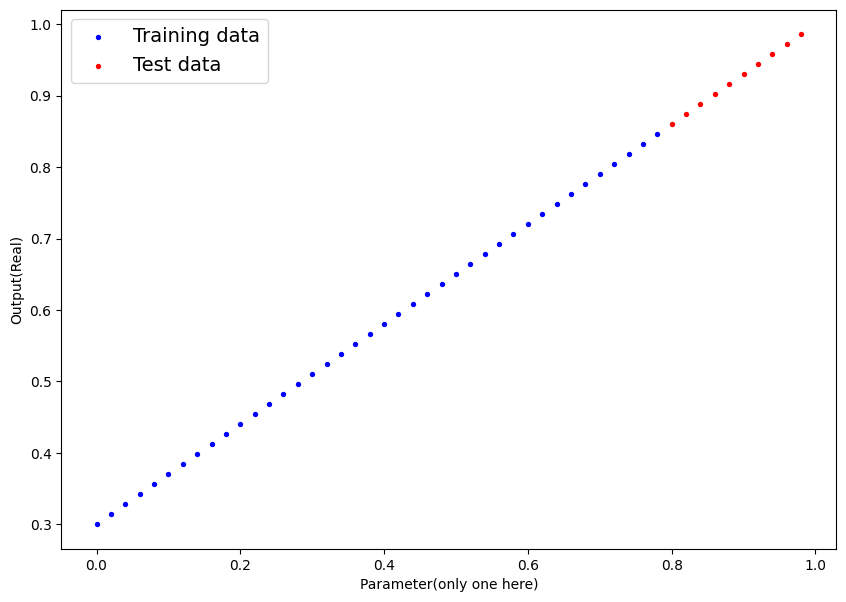

In [30]:
plot_prediction(X_train,y_train,X_test,y_test)

# 2. Build Model

Our first PyTorch model!

Model that have parameter of A and B

in linear equation of Y=a+bX

Heavy use of OOPS


what our model does

* Start with random values(weight and bias)
* Look at training data and adjust the random values to better represent(or ger closer to) to the ideal values(the weight and bias values we used to create the data)


How does it do so???

Through two main algos:

1. Gradient descent
2. Backpropogation

In [33]:
#Create class linear regression model class
class LinearRegressionModel(nn.Module):  #<-almost everything in pytorch inherits from nn.Module
  def __init__(self):
    super().__init__()

    #Initialise the model parameters
    self.weights=nn.Parameter(torch.randn(1, #<-starts with a random weight and try to adjust it to the ideal weight
                                          requires_grad=True, #<-can this parameter be updated via gradient descenet
                                          dtype=torch.float)) #<-Pytorch loves the datatype torch.float32

    self.bias=nn.Parameter(torch.randn(1, #<-starts with a random bias and try to adjust it to the ideal bias
                                       requires_grad=True, #<-can this parameter be updated via gradient descent
                                       dtype=torch.float   #<-Pytoch loves the datatype torch.float32
                                       ))

    #Foward method to define the computation in the model
    def forward(self,x:torch.Tensor)->torch.Tensor: #<- "x" is the input data
        return self.weights*x+self.bias  #this is the linear regression formula



#Pytorch model building essential


* torch.nn - contains all of the buiding blocks for computational graphs(a neural network can be considered a computational graphs)

* torch.nn.Parameter - What parameters should our model try and learn , often a Pytorch layer from torch.nn will set these for us

* torch.nn.Module - The base class for all neural network modules , if you subclass it, you should overwrite forward()

* torch.optim -this where the optimizers in pytorch lives
, they will help with gradient descent

* def forward() -All nn.Module subclasses require you to forward(), this method defines what happens in the forward computation

###  checking the contents of our pytorch model


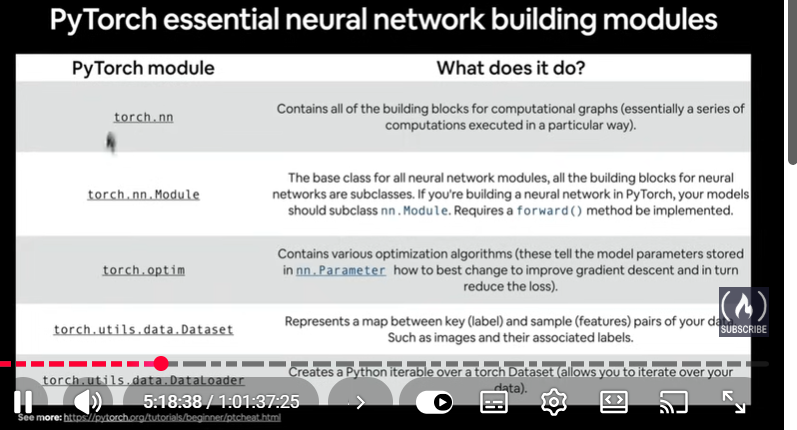

###  checking the contents of our pytorch model


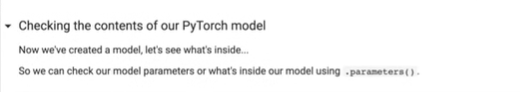

In [46]:
torch.randn(1)

tensor([0.2345])

In [51]:
#create a random seed
torch.manual_seed(42)

#create an instance of the Modile
model_0=LinearRegressionModel()
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [48]:
model_0.parameters

<bound method Module.parameters of LinearRegressionModel()>

In [53]:
#List name parameters
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [54]:
weight,bias

(0.7, 0.3)